# Strict metrics

Notebook 01 ended with a list of things the reward does not see. Here I add strict checks next to the reward and run everything on 600 random targets with simulated OCR errors. Still no model.

## Rewards

From notebook 01, now taking the target directly instead of the prompt.

In [1]:
import random
import statistics
import string

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


def edit_distance(a, b):
    previous = list(range(len(b) + 1))
    for i, char_a in enumerate(a, start=1):
        current = [i]
        for j, char_b in enumerate(b, start=1):
            current.append(
                min(previous[j] + 1, current[j - 1] + 1, previous[j - 1] + (char_a != char_b))
            )
        previous = current
    return previous[-1]


def substring_distance(target, text):
    previous = [0] * (len(text) + 1)
    for i, char_t in enumerate(target, start=1):
        current = [i]
        for j, char_x in enumerate(text, start=1):
            current.append(
                min(previous[j] + 1, current[j - 1] + 1, previous[j - 1] + (char_t != char_x))
            )
        previous = current
    return min(previous)


def squash(text):
    return text.replace(" ", "").lower()


def official_reward(target, ocr_text):
    want, got = squash(target), squash(ocr_text)
    if want in got:
        return 1.0
    return 1 - min(edit_distance(got, want), len(want)) / len(want)


def aligned_reward(target, ocr_text):
    want = squash(target)
    return 1 - substring_distance(want, squash(ocr_text)) / len(want)

## Strict checks

- exact match: the target words are there in order, as whole words, with the same case
- CER: edit distance to the whole OCR text divided by the target length. Case-sensitive, and extra text counts as errors, so it can go above 1
- word accuracy: share of target words found in order

In [2]:
def exact_match(target, ocr_text):
    want, got = target.split(), ocr_text.split()
    return any(got[i : i + len(want)] == want for i in range(len(got) - len(want) + 1))


def cer(target, ocr_text):
    return edit_distance(target, " ".join(ocr_text.split())) / len(target)


def word_accuracy(target, ocr_text):
    want, got = target.split(), ocr_text.split()
    lcs = [0] * (len(got) + 1)
    for word in want:
        row = [0]
        for j, candidate in enumerate(got, start=1):
            row.append(lcs[j - 1] + 1 if word == candidate else max(lcs[j], row[j - 1]))
        lcs = row
    return lcs[-1] / len(want)


METRICS = {
    "official": official_reward,
    "aligned": aligned_reward,
    "exact": exact_match,
    "cer": cer,
    "word acc": word_accuracy,
}


def mean_scores(pairs):
    # pairs is a list of (target, ocr_text)
    return {
        name: statistics.mean(float(metric(target, ocr_text)) for target, ocr_text in pairs)
        for name, metric in METRICS.items()
    }


for ocr_text in ["Open Late", "open late", "Open Late Open Lat", "Open"]:
    print(f"{ocr_text!r:<22}", {name: round(float(m("Open Late", ocr_text)), 2) for name, m in METRICS.items()})

'Open Late'            {'official': 1.0, 'aligned': 1.0, 'exact': 1.0, 'cer': 0.0, 'word acc': 1.0}
'open late'            {'official': 1.0, 'aligned': 1.0, 'exact': 0.0, 'cer': 0.22, 'word acc': 0.0}
'Open Late Open Lat'   {'official': 1.0, 'aligned': 1.0, 'exact': 1.0, 'cer': 1.0, 'word acc': 1.0}
'Open'                 {'official': 0.5, 'aligned': 0.5, 'exact': 0.0, 'cer': 0.56, 'word acc': 0.5}


## Targets

600 random targets, 1 to 6 words, in lower, Title and UPPER case.

In [3]:
WORDS = """apple river candle orange window garden silver forest button castle planet rocket
bridge market coffee dragon engine guitar harbor island jacket lemon maple ocean pencil rabbit
tunnel valley yellow anchor basket desert eagle hammer jungle ladder magnet parrot ribbon sunset
tiger velvet willow cherry honey mango pearl storm wheat arrow cloud frost light night water""".split()

rng = random.Random(0)
targets = []
for i in range(600):
    words = rng.sample(WORDS, i % 6 + 1)
    casing = (str.lower, str.title, str.upper)[i // 6 % 3]
    targets.append(casing(" ".join(words)))


def length_group(target):
    n = len(target.split())
    return "short" if n == 1 else "medium" if n <= 3 else "long"


print(len(targets))
for target in targets[:6] + targets[6:9]:
    print(" ", target)

600
  water
  pencil wheat
  tunnel candle engine
  eagle desert rabbit cloud
  night island basket maple parrot
  market eagle button harbor light wheat
  Silver
  Sunset Frost
  Engine Jungle Mango


## Typical mistakes

Each mistake is applied to all 600 targets, the table shows the mean.

In [4]:
def typo(text):
    i = len(text) // 2
    if text[i] == " ":
        i += 1
    wrong = "o" if text[i].lower() == "x" else "x"
    if text[i].isupper():
        wrong = wrong.upper()
    return text[:i] + wrong + text[i + 1 :]


MISTAKES = {
    "no errors": lambda t: t,
    "case swapped": str.swapcase,
    "spaces dropped": lambda t: t.replace(" ", ""),
    "extra text around": lambda t: f"SALE {t} est 1987",
    "second copy with a typo": lambda t: f"{t} {typo(t)}",
    "one typo": typo,
    "one typo, extra text around": lambda t: f"SALE {typo(t)} est 1987",
    "last word missing": lambda t: " ".join(t.split()[:-1]),
}

print(f"{'':<30}" + "".join(f"{name:>10}" for name in METRICS))
for name, mistake in MISTAKES.items():
    scores = mean_scores([(t, mistake(t)) for t in targets])
    print(f"{name:<30}" + "".join(f"{value:>10.2f}" for value in scores.values()))

                                official   aligned     exact       cer  word acc
no errors                           1.00      1.00      1.00      0.00      1.00
case swapped                        1.00      1.00      0.00      0.91      0.00
spaces dropped                      1.00      1.00      0.17      0.09      0.17
extra text around                   1.00      1.00      1.00      0.96      1.00
second copy with a typo             1.00      1.00      1.00      1.07      1.00
one typo                            0.93      0.93      0.00      0.07      0.59
one typo, extra text around         0.33      0.93      0.00      1.02      0.59
last word missing                   0.59      0.59      0.00      0.42      0.59


Both rewards give 1.0 to swapped case, dropped spaces, extra text and a second copy with a typo. Each of these is caught by at least one strict check: exact match catches case and spaces, CER catches extra text.

One typo with extra text around is where the two rewards split: 0.33 official, 0.93 aligned. Same cliff as in notebook 01, now averaged over 600 targets.

## Random character errors

Each character is broken with some probability: replaced (60%), dropped (20%) or followed by an extra character (20%). 20 runs per target.

In [5]:
def letters_like(ch):
    return string.ascii_uppercase if ch.isupper() else string.ascii_lowercase


def corrupt(text, p, rng):
    out = []
    for ch in text:
        if ch == " " or rng.random() >= p:
            out.append(ch)
            continue
        kind = rng.random()
        if kind < 0.6:
            out.append(rng.choice([c for c in letters_like(ch) if c != ch]))
        elif kind < 0.8:
            continue
        else:
            out += [ch, rng.choice(letters_like(ch))]
    return "".join(out)


RATES = [0, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
rng = random.Random(1)
sweep = [mean_scores([(t, corrupt(t, p, rng)) for t in targets for _ in range(20)]) for p in RATES]

print(f"{'error rate':<12}" + "".join(f"{name:>10}" for name in METRICS))
for p, scores in zip(RATES, sweep):
    print(f"{p:<12.0%}" + "".join(f"{value:>10.2f}" for value in scores.values()))

error rate    official   aligned     exact       cer  word acc
0%                1.00      1.00      1.00      0.00      1.00
1%                0.99      0.99      0.83      0.01      0.95
2%                0.98      0.98      0.68      0.02      0.89
5%                0.95      0.95      0.41      0.05      0.75
10%               0.90      0.90      0.20      0.09      0.55
15%               0.85      0.85      0.11      0.13      0.40
20%               0.80      0.81      0.07      0.18      0.28
30%               0.71      0.71      0.03      0.27      0.14


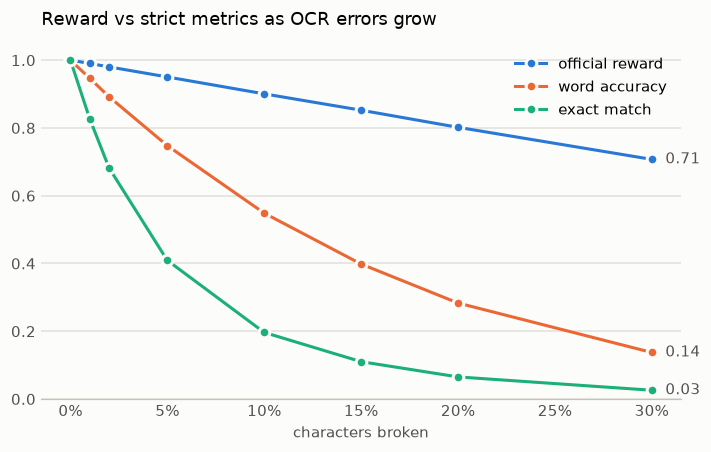

In [6]:
SURFACE, INK, GRID = "#fcfcfb", "#52514e", "#e1e0d9"
LINES = {"official": "#2a78d6", "word acc": "#eb6834", "exact": "#1baf7a"}
LABELS = {"official": "official reward", "word acc": "word accuracy", "exact": "exact match"}

fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=110, facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for name, color in LINES.items():
    values = [scores[name] for scores in sweep]
    ax.plot(RATES, values, color=color, lw=2, marker="o", ms=7, mec=SURFACE, mew=2, label=LABELS[name])
    ax.annotate(f"{values[-1]:.2f}", (RATES[-1], values[-1]), xytext=(9, 0),
                textcoords="offset points", va="center", color=INK)

ax.set_ylim(0, 1.05)
ax.set_xlabel("characters broken", color=INK)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="y", color=GRID, lw=1)
ax.set_axisbelow(True)
ax.tick_params(length=0, colors=INK)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.legend(frameon=False, loc="upper right")
ax.set_title("Reward vs strict metrics as OCR errors grow", loc="left", pad=12)
plt.show()

The reward drops in a straight line, about 0.01 for each percent of broken characters. Exact match drops much faster: at 5% errors the reward is still 0.95 but less than half of the targets are fully correct.

Official and aligned are almost the same here because there is no extra text in the image.

## By target length

Same thing at 5% broken characters, split by number of words.

In [7]:
rng = random.Random(2)
print(f"{'':<10}{'targets':>8}{'official':>10}{'exact':>8}")
for group in ("short", "medium", "long"):
    subset = [t for t in targets if length_group(t) == group]
    scores = mean_scores([(t, corrupt(t, 0.05, rng)) for t in subset for _ in range(20)])
    print(f"{group:<10}{len(subset):>8}{scores['official']:>10.2f}{scores['exact']:>8.2f}")

           targets  official   exact
short          100      0.95    0.73
medium         200      0.95    0.48
long           300      0.95    0.25


Same error rate, same reward in every group, but exact match goes from 0.73 for single words to 0.25 for 4-6 words. A single mean over all targets hides this.

## Notes for later

- always report exact match next to the reward, the reward alone looks too good
- CER is the only one that sees extra and duplicated text
- report by length group
- the error model here is uniform and made up. Real OCR and real models fail in their own ways, check again on real images